In [1]:
#import some standard python packages that will be useful
import array
import random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt


# import deap packages required
from deap import algorithms
from deap import base
from deap import creator
from deap import tools

In [2]:
NUMBER_OF_CITIES = 100
MIN_distance = 50
MAX_distance = 2000

distances = np.zeros((NUMBER_OF_CITIES, NUMBER_OF_CITIES))
for city in range(NUMBER_OF_CITIES):
    cities = [ i for i in range(NUMBER_OF_CITIES) if not i == city ]
    for to_city in cities:
        distances[to_city][city] = \
            distances[city][to_city] = random.randint(MIN_distance, MAX_distance)



In [3]:
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)
toolbox = base.Toolbox()



## permutation setup for individual
toolbox.register("indices", 
                 random.sample, 
                 range(NUMBER_OF_CITIES), 
                 NUMBER_OF_CITIES)

toolbox.register("individual", 
                 tools.initIterate, 
                 creator.Individual, toolbox.indices)


#  a population consist of a list of individuals
toolbox.register("population", tools.initRepeat, list, toolbox.individual)




In [4]:
def evalTSP(individual):

    total_distance = 0
    

    for city in range(0, len(individual)):
        start = individual[city]
        
        if city < (NUMBER_OF_CITIES-1):
            end = individual[city+1]
        else:
            end = individual[0]
            
     
        dist = distances[start][end]
        total_distance = total_distance + dist
        
    return total_distance,
        

In [5]:
def mutateSwap(individual):
    p1 = random.randint(0,len(individual)-1)
    p2 = random.randint(0,len(individual)-1)
    city1 = individual[p1]
    city2 = individual[p2]
    
    individual[p1]=city2
    individual[p2]=city1
    
    return individual,

In [6]:
def mutateInvert(individual):
    p1 = random.randint(0,len(individual)-1)
    p2 = random.randint(0,len(individual)-1)
   
    #ensure p1 < p2
    if p1 > p2:
        temp=p1
        p1=p2
        p2=temp
    
    individual[p1:p2] = reversed(individual[p1:p2])

    return individual,

In [7]:


# register all operators we need with the toolbox
toolbox.register("evaluate", evalTSP)
toolbox.register("mate", tools.cxOrdered)
#toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.05)
toolbox.register("mutate", mutateInvert)
toolbox.register("select", tools.selTournament, tournsize=2)


# main function

def main():
    
    # choose a population size: e.g. 200
    pop = toolbox.population(n=5)
    
    # keep track of the single best solution found
    hof = tools.HallOfFame(1)
 
    # create a statistics object: we can log what ever statistics we want using this. We use the numpy Python library
    # to calculate the stats and label them with convenient labels
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("avg", np.mean)
    stats.register("std", np.std)
    stats.register("min", np.min)
    stats.register("max", np.max)
    
    # run the algorithm: we need to tell it what parameters to use
    # cxpb = crossover probability; mutpb = mutation probability; ngen = number of iterations
    pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.6, mutpb=1.0, ngen=100, 
                                   stats=stats, halloffame=hof, verbose=True)
    
    return pop, log, hof


##############################
# run the main function 
pop, log, hof = main()

##############################


best = hof[0].fitness.values[0]   # best fitness found is stored at index 0 in the hof list


# look in the logbook to see what generation this was found at

min = log.select("min")  # max fitness per generation stored in log

for i in range(200):  # set to ngen
        fit = min[i]
        if fit == best:
            break        
        
print("max fitness found is %s at gen %s " % (best, i))
 



gen	nevals	avg   	std    	min  	max   
0  	5     	100946	4419.39	94800	107415
1  	5     	96331.4	2133.56	92952	99156 
2  	5     	97634.4	2637.87	93653	101404
3  	5     	97377.6	1463.36	95696	99664 
4  	5     	96078.8	1707.03	93315	98182 
5  	5     	95981.6	2106.22	91864	97733 
6  	5     	94893.6	1615.03	92925	97034 
7  	5     	95164.8	2013.21	92970	98393 
8  	5     	93328  	602.076	92703	94417 
9  	5     	93103.2	1161.8 	91657	95042 
10 	5     	93662.6	887.944	92197	94645 
11 	5     	94170.4	788.617	93037	95273 
12 	5     	95371.8	2294.71	93110	99755 
13 	5     	96497.6	1747.99	94240	99080 
14 	5     	94524.8	1080.87	92925	95663 
15 	5     	93163.6	1522.51	90205	94520 
16 	5     	92163.2	2041.4 	89674	94757 
17 	5     	91659.4	1736.13	89668	94250 
18 	5     	91994.4	2823.72	89207	96019 
19 	5     	89445  	1166.27	87851	90880 
20 	5     	88854.2	1324.65	87673	90801 
21 	5     	89661.6	1101.14	87673	91075 
22 	5     	88783.8	1580.69	85723	90069 
23 	5     	88756.4	2379.23	84858	91001 
24

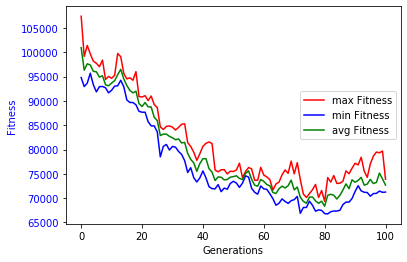

In [8]:


# code for plotting

gen = log.select("gen")
fit_max = log.select("max")
fit_min = log.select("min")
fit_avg = log.select("avg")

fig, ax1 = plt.subplots()
line1 = ax1.plot(gen, fit_max, "b-", label="max Fitness", color="r")
line2 = ax1.plot(gen, fit_min, "b-", label="min Fitness", color="b")
line3 = ax1.plot(gen , fit_avg, "b-", label="avg Fitness", color="g")
ax1.set_xlabel("Generations")
ax1.set_ylabel("Fitness", color="b")
for tl in ax1.get_yticklabels():
    tl.set_color("b")

    
lns = line1+line2+line3
labs = [l.get_label() for l in lns]
ax1.legend(lns, labs, loc="center right")



